In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math

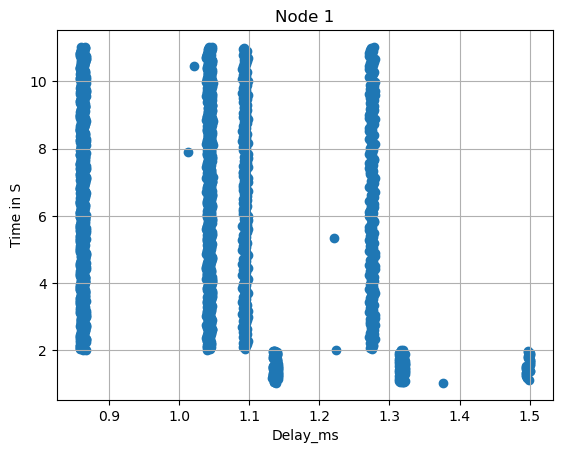

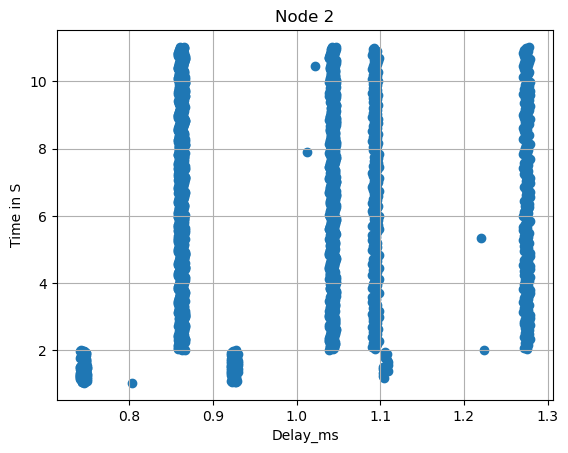

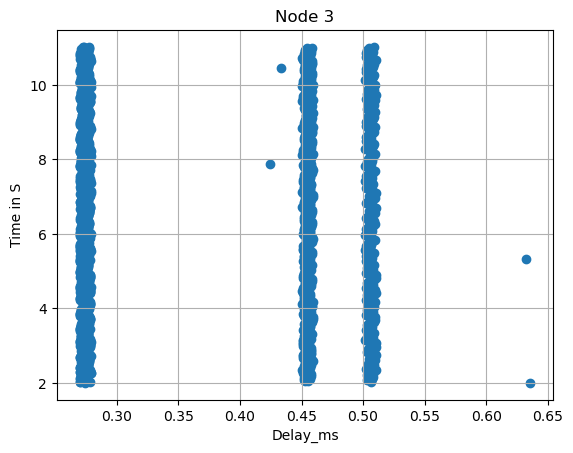

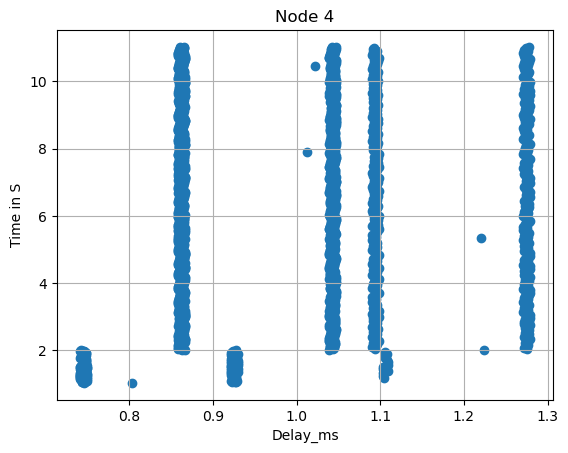

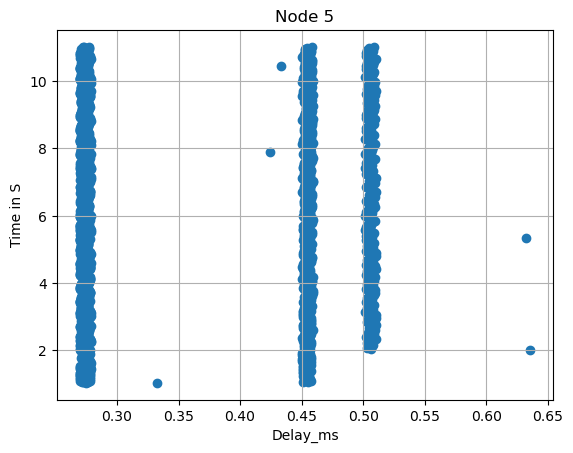

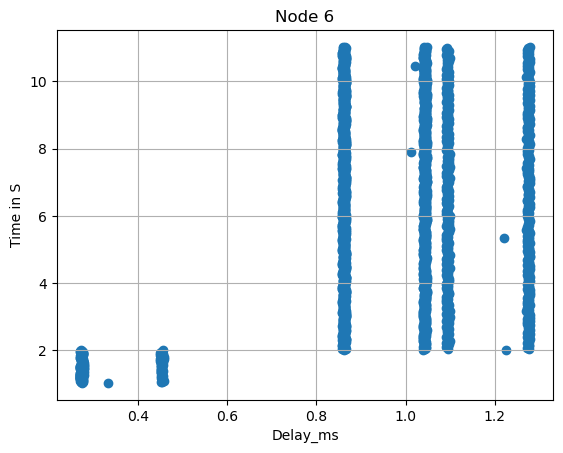

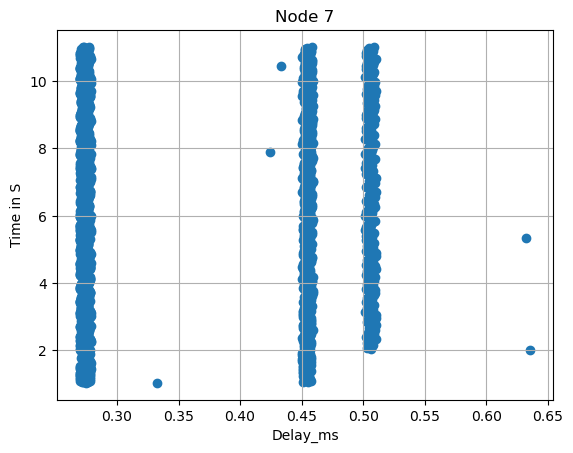

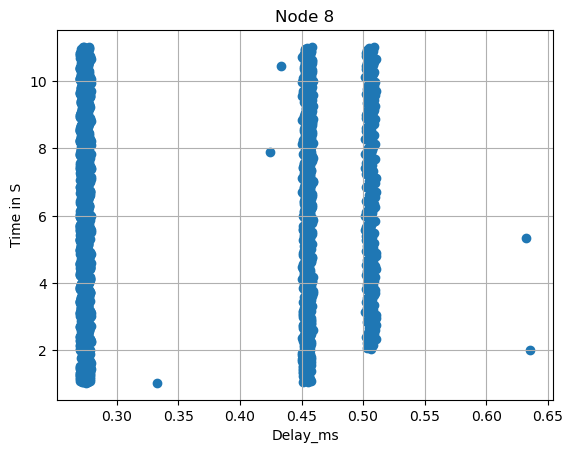

In [24]:
dplt = pd.DataFrame(columns=["nSta","Avg Delay"])
colors = np.random.rand(1006)
area = (30 * np.random.rand(1006))**2
for mcs in range(11, 12):
    for nSta in range(8, 9):
        for node in range(1, 9): 
            dt = pd.read_csv("results/1-downlink-withOfdma-{nSta}-mcs{mcs}/00:00:00:00:00:0{node}".format(nSta=nSta, mcs=mcs,node=node), delimiter="\t")
            #dplt.loc[nSta] = [nSta, dt["Avg_delay_ms"].mean()]
            plt.figure()
            plt.scatter(dt["Delay_ms"], dt["Time_s"])# s=area, c=colors, alpha=0.5)
                        #linestyle='dashed', linewidth = 2, marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
            plt.ylabel("Time in S")
            plt.xlabel("Delay_ms")
            plt.grid(True)
            #plt.legend()
            plt.title("Node {node}".format(node=node))
            plt.savefig("Time_vrs_delay_scatter_mcs{node}.png".format(node=node), dpi=500)

In [3]:
dt

,Time_s,Packet_ID,Delay_ms
0,1.00203,125,2.029230
1,1.00528,443,0.282463
2,1.01079,722,0.793386
3,1.01595,1242,0.951258
4,1.02054,1667,0.539582
...,...,...,...
1001,6.00528,158180,0.275198
1002,6.01027,158351,0.270116
1003,6.01527,158492,0.273040
1004,6.02028,158663,0.276958


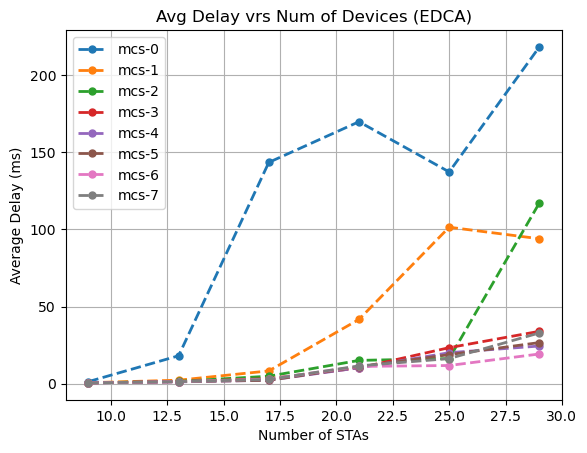

In [14]:

for mcs in range(0, 8):
    dplt = pd.DataFrame(columns=["nSta","Avg Delay", "Std"])
    for nSta in range(9, 31, 4):
        dt = pd.read_csv("results_limits/1-withOfdma-{nSta}-mcs{mcs}/per_sta_stats.out".format(nSta=nSta, mcs=mcs), delimiter="\t")
        dplt.loc[nSta] = [nSta, dt["Avg_delay_ms"].mean(), dt["Avg_delay_ms"].std()]
        #print(dplt)
    plt.plot(dplt["nSta"], dplt["Avg Delay"], linestyle='dashed', linewidth = 2,
         marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Average Delay (ms)")
    #plt.errorbar(dplt["nSta"], dplt["Avg Delay"],yerr=dplt["Std"], fmt='o', capsize=5,
     #            label="mcs-{mcs}".format(mcs=mcs))
    plt.legend()
    plt.grid(True)
    plt.title("Avg Delay vrs Num of Devices (EDCA)")
    #plt.savefig("delay_vrs_Ndev_mcs8-11.png", dpi=500)

/usr/lib/python3.10/site-packages/matplotlib/cbook/__init__.py:1335: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return np.asarray(x, float)
/usr/lib/python3.10/site-packages/matplotlib/cbook/__init__.py:1335: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return np.asarray(x, float)
/usr/lib/python3.10/site-packages/matplotlib/cbook/__init__.py:1335: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return np.asarray(x, float)
/usr/lib/python3.10/site-packages/matplotlib/cbook/__init__.py:1335: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return np.asarray(x, float)


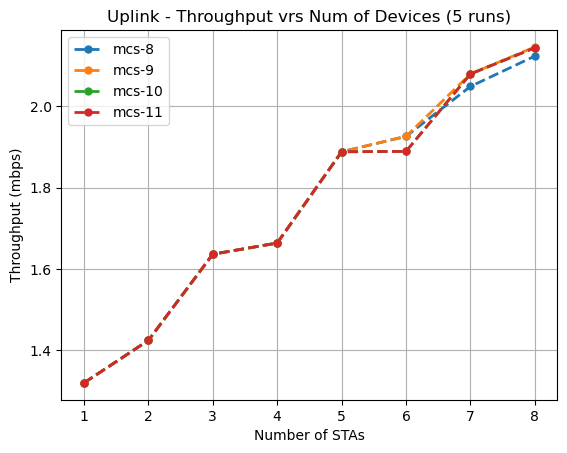

In [26]:

dt = None
for mcs in range(8, 12):
    dplt = pd.DataFrame()
    dtl = {
    "nSta":[],
    "throughput" :[]
    }
    
    for nSta in range(1, 9):
        dt = pd.read_csv("results/1-withOfdma-{nSta}-mcs{mcs}/throughput.out".format(nSta=nSta, mcs=mcs), delimiter="\t")
        #print(dt)
        dtl["nSta"].append(nSta)
        dtl["throughput"].append (dt["Throughput_Mbps"])
    dplt = pd.DataFrame(dtl)

    #plt.figure()
    plt.plot(dplt["nSta"], dplt["throughput"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Throughput (mbps)")
    plt.legend()
    plt.grid(True)
    plt.title("Uplink - Throughput vrs Num of Devices (5 runs)")
    plt.savefig("throughput_vrs_Ndev_mcs8-11.png", dpi=500)

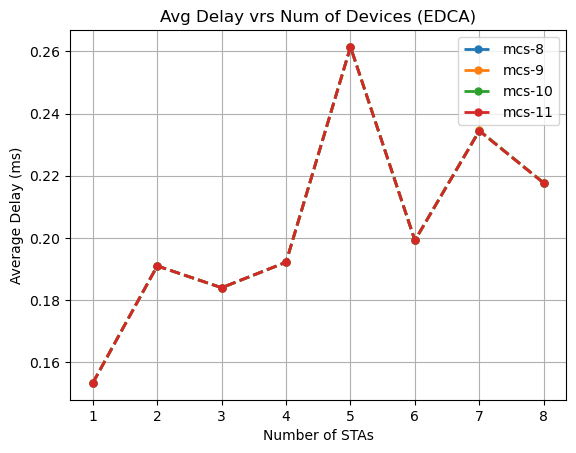

In [43]:
dplt = pd.DataFrame()
dtl = {}
dt = None
for mcs in range(8, 12):
    for runs in range(1, 6):
        dtl["nSta"] = []
        dtl["Avg Delay_{runs}".format(runs=runs)] = []
        for nSta in range(1, 9):
            dt = pd.read_csv("results/{runs}-withEdca-{nSta}-mcs{mcs}/per_sta_stats.out".format(nSta=nSta, mcs=mcs, runs=runs), delimiter="\t")
            #print(type(dt))
            dtl["nSta"].append(nSta)
            #dat = dt[dt["Avg_delay_ms"] < 50]
            dtl["Avg Delay_{runs}".format(runs=runs)].append (dt["Avg_delay_ms"]. mean())
    dplt = pd.DataFrame(dtl)
    dplt["Avg Delay"] = dplt.iloc[:, 1:].mean(axis=1)
    plt.plot(dplt["nSta"], dplt["Avg Delay"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Average Delay (ms)")
    plt.legend()
    plt.grid(True)
    plt.title("Avg Delay vrs Num of Devices (EDCA)")
    #plt.savefig("delay_vrs_Ndev_mcs8-11.png", dpi=500)

In [39]:
dplt

,nSta,Avg Delay_1,Avg Delay_2,Avg Delay_3,Avg Delay_4,Avg Delay_5,Avg Delay
0,1,0.152184,0.153684,0.153796,0.153318,0.153942,0.153385
1,2,0.166675,0.166218,0.225746,0.166045,0.230348,0.191006
2,3,0.174820,0.178699,0.175323,0.173795,0.217349,0.183997
3,4,0.180272,0.232552,0.177959,0.177840,0.192447,0.192214
4,5,0.234029,0.181166,0.183362,0.204760,0.503857,0.261435
5,6,0.199544,0.190629,0.203501,0.195289,0.207159,0.199224
6,7,0.206027,0.262760,0.215466,0.227088,0.260702,0.234408
7,8,0.219574,0.203568,0.215597,0.231641,0.218013,0.217679


**Error Bar**

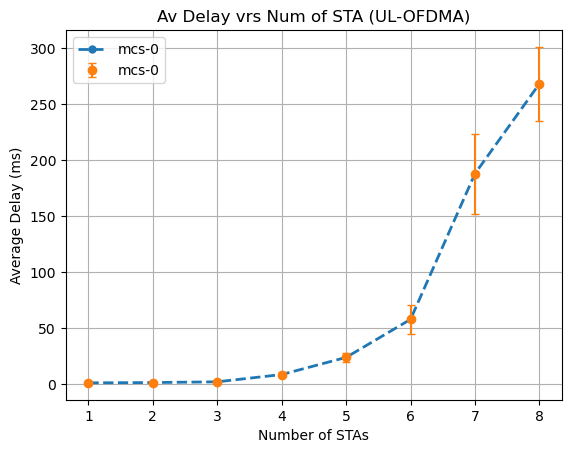

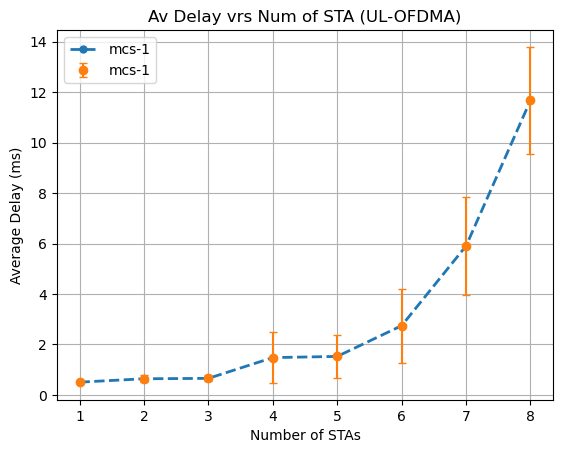

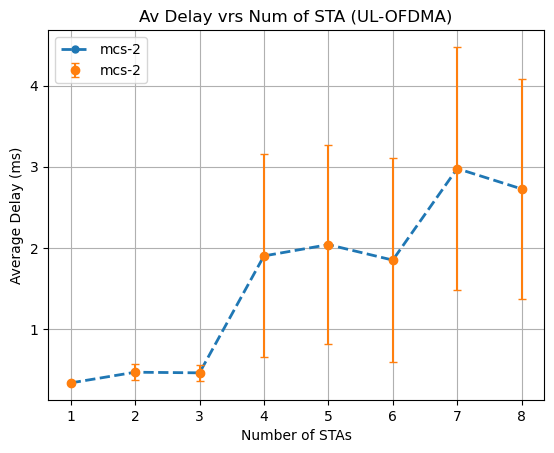

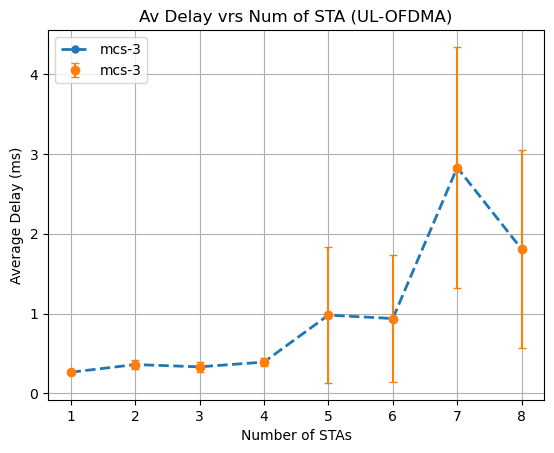

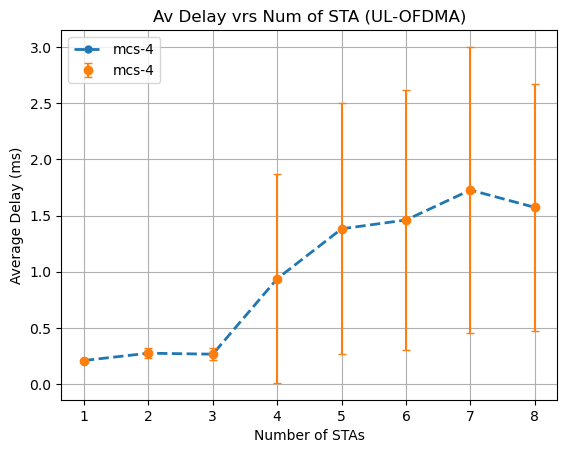

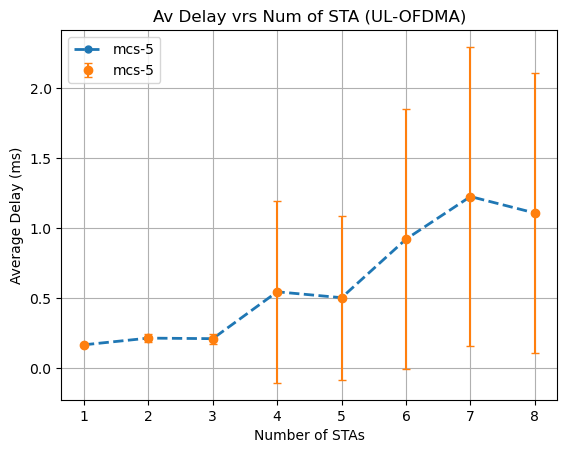

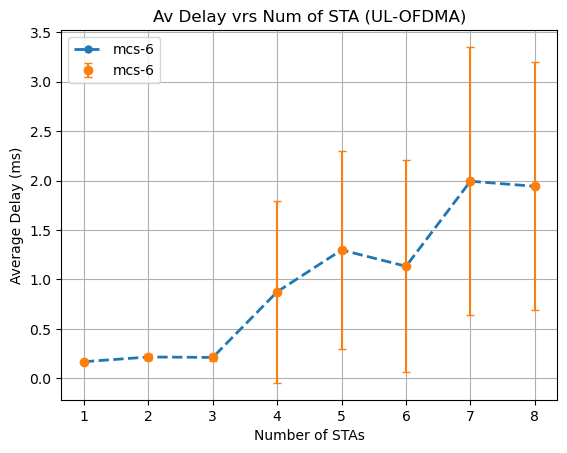

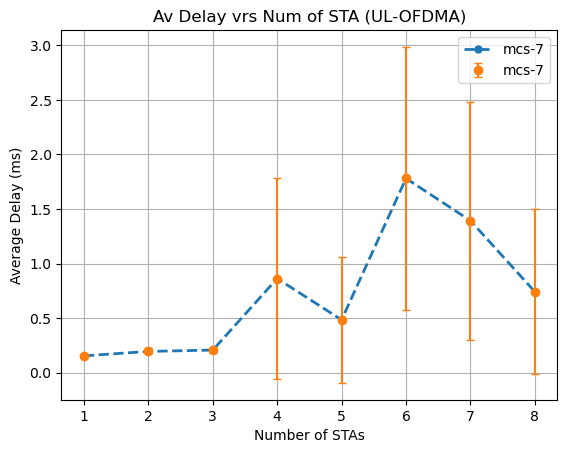

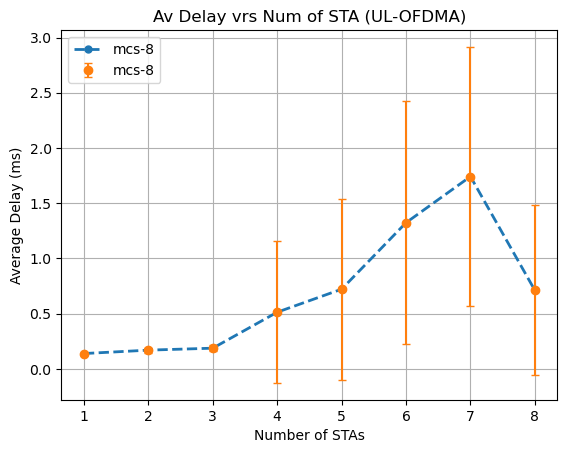

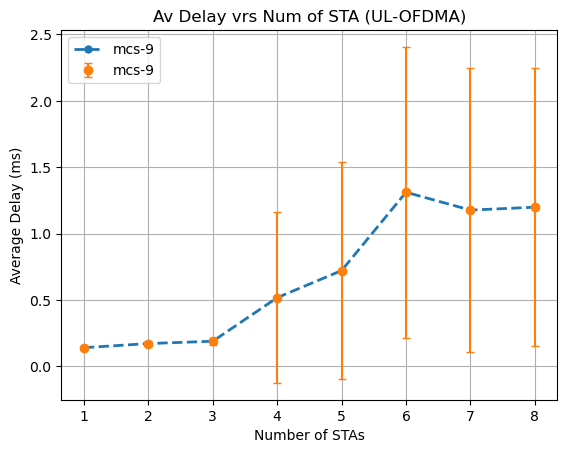

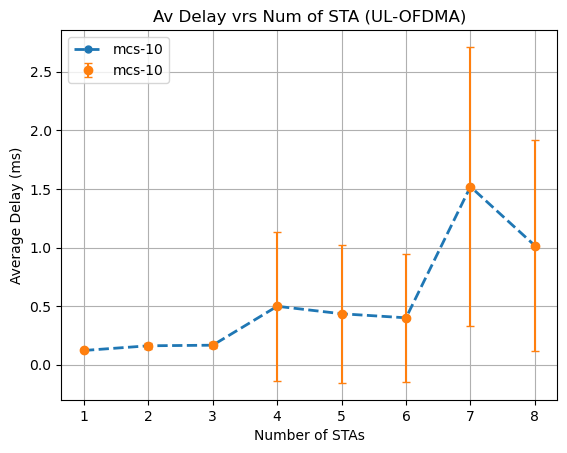

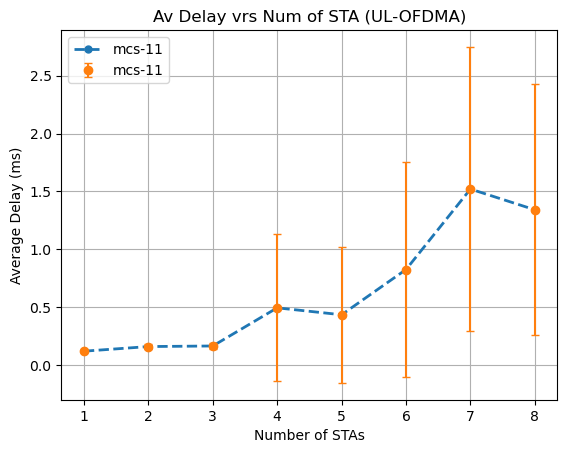

In [34]:
dplt = pd.DataFrame()

dtl = {}
dt = None
for mcs in range(0, 12):
    for runs in range(1, 6):
        dtl["nSta"] = []
        dtl["Avg Delay_{runs}".format(runs=runs)] = []
        dtl["Std_{runs}".format(runs=runs)] = []
        dtl["Var_{runs}".format(runs=runs)] = []
        for nSta in range(1, 9):
            dt = pd.read_csv("results_NOedca/{runs}-uplinkOFDMA-{nSta}-mcs{mcs}/per_sta_stats.out".format(nSta=nSta, mcs=mcs, runs=runs), delimiter="\t")
            #print(type(dt))
            dtl["nSta"].append(nSta)
            #dat = dt[dt["Avg_delay_ms"] < 50]
            dtl["Avg Delay_{runs}".format(runs=runs)].append (dt["Avg_delay_ms"]. mean())
            dtl["Std_{runs}".format(runs=runs)].append (dt["Avg_delay_ms"].std() )
            dtl["Var_{runs}".format(runs=runs)].append (dt["Avg_delay_ms"].var() )
    dplt = pd.DataFrame(dtl)
    dplt["Avg Delay"] = dplt[['Avg Delay_1','Avg Delay_2','Avg Delay_3','Avg Delay_4','Avg Delay_5']].mean(axis=1)
    dplt["sum_var_std"] = np.sqrt(dplt[['Var_1','Var_2','Var_3','Var_4','Var_5']].sum(axis=1)) / 5
    plt.figure()
    plt.plot(dplt["nSta"], dplt["Avg Delay"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Average Delay (ms)")
    plt.errorbar(dplt["nSta"], dplt["Avg Delay"],yerr=dplt["sum_var_std"], fmt='o', capsize=3,
                 label="mcs-{mcs}".format(mcs=mcs))
    plt.legend()
    plt.grid(True)
    plt.title("Av Delay vrs Num of STA (UL-OFDMA)")
    #plt.savefig("UL-OFDMA-NOEDCA-ErrorBar_mcs{mcs}.png".format(mcs=mcs), dpi=500)    
    


In [29]:
0.015627 + 0.015150 + 0.015378 + 0.015210 + 0.016419

0.077784

In [45]:
np.sqrt(0.077784) / 5

0.05577956615105571

In [33]:
0.038892 / 5

0.0077784

In [35]:
dplt

,nSta,Avg Delay_1,Std_1,Var_1,Avg Delay_2,Std_2,Var_2,Avg Delay_3,Std_3,Var_3,Avg Delay_4,Std_4,Var_4,Avg Delay_5,Std_5,Var_5,Avg Delay,sum_var_std
0,1,0.152184,0.125008,0.015627,0.153684,0.123086,0.015150,0.153796,0.124008,0.015378,0.153318,0.123327,0.015210,0.153942,0.128136,0.016419,0.153385,0.055779
1,2,0.166675,0.176683,0.031217,0.166218,0.173565,0.030125,0.225746,0.278753,0.077704,0.166045,0.174054,0.030295,0.230348,0.156615,0.024528,0.191006,0.088061
2,3,0.174820,0.214125,0.045849,0.178699,0.219538,0.048197,0.175323,0.220492,0.048617,0.173795,0.216750,0.046981,0.217349,0.200985,0.040395,0.183997,0.095925
3,4,0.180272,0.247273,0.061144,0.232552,0.285529,0.081527,0.177959,0.248976,0.061989,0.177840,0.249472,0.062236,0.192447,0.240284,0.057737,0.192214,0.113953
4,5,0.234029,0.260218,0.067713,0.181166,0.278160,0.077373,0.183362,0.283043,0.080114,0.204760,0.270292,0.073058,0.503857,0.248181,0.061594,0.261435,0.119975
5,6,0.199544,0.297489,0.088499,0.190629,0.316406,0.100113,0.203501,0.301769,0.091064,0.195289,0.308542,0.095198,0.207159,0.292799,0.085731,0.199224,0.135736
6,7,0.206027,0.324597,0.105363,0.262760,0.327223,0.107075,0.215466,0.383076,0.146747,0.227088,0.388131,0.150645,0.260702,0.310521,0.096423,0.234408,0.155725
7,8,0.219574,0.353633,0.125056,0.203568,0.348499,0.121451,0.215597,0.355605,0.126455,0.231641,0.354680,0.125798,0.218013,0.345152,0.119130,0.217679,0.157212


In [78]:
dplt

,nSta,Avg Delay_1,Std_1,Var_1,Avg Delay_2,Std_2,Var_2,Avg Delay_3,Std_3,Var_3,Avg Delay_4,Std_4,Var_4,Avg Delay_5,Std_5,Var_5,Avg Delay,std,sum_var
0,1,0.159077,0.115215,0.013274,0.160563,0.113628,0.012911,0.160227,0.114128,0.013025,0.160307,0.113445,0.012870,0.160912,0.118653,0.014078,0.160217,0.002148,0.066159
1,2,0.379543,0.012130,0.000147,0.382131,0.010936,0.000120,0.383639,0.008962,0.000080,0.384176,0.011363,0.000129,0.384942,0.010946,0.000120,0.382886,0.001170,0.000596
2,3,0.530900,0.012149,0.000148,0.533809,0.005688,0.000032,0.535186,0.017409,0.000303,0.529027,0.018877,0.000356,0.531505,0.003887,0.000015,0.532086,0.006735,0.000855
3,4,0.703896,0.039276,0.001543,0.707017,0.045063,0.002031,0.702185,0.038916,0.001514,0.685693,0.046686,0.002180,0.687912,0.035909,0.001289,0.697340,0.004526,0.008557
4,5,0.852954,0.049874,0.002487,0.862571,0.048928,0.002394,0.866993,0.042598,0.001815,0.856122,0.074387,0.005533,0.851634,0.032945,0.001085,0.858055,0.015340,0.013315
5,6,1.030606,0.074475,0.005547,1.021420,0.087168,0.007598,1.026015,0.048728,0.002374,1.002020,0.045945,0.002111,1.008600,0.077926,0.006073,1.017732,0.018433,0.023703
6,7,1.188221,0.111612,0.012457,1.200310,0.069077,0.004772,1.196366,0.071809,0.005157,1.175669,0.045788,0.002097,1.176514,0.127335,0.016214,1.187416,0.033412,0.040696
7,8,1.378752,0.141357,0.019982,1.385028,0.127820,0.016338,1.345092,0.120172,0.014441,1.342529,0.072627,0.005275,1.352211,0.174593,0.030483,1.360722,0.036995,0.086518


**Throughput**

In [67]:
dplt

,nSta,Avg Delay_1,Std_1,Var_1,Avg Delay_2,Std_2,Var_2,Avg Delay_3,Std_3,Var_3,Avg Delay_4,Std_4,Var_4,Avg Delay_5,Std_5,Var_5,Avg Delay,std,sum_var
0,1,0.159077,0.115215,0.013274,0.160563,0.113628,0.012911,0.160227,0.114128,0.013025,0.160307,0.113445,0.012870,0.160912,0.118653,0.014078,0.096154,0.061482,1.599950
1,2,0.379543,0.012130,0.000147,0.382131,0.010936,0.000120,0.383639,0.008962,0.000080,0.384176,0.011363,0.000129,0.384942,0.010946,0.000120,0.131291,0.177963,2.278618
2,3,0.530900,0.012149,0.000148,0.533809,0.005688,0.000032,0.535186,0.017409,0.000303,0.529027,0.018877,0.000356,0.531505,0.003887,0.000015,0.181286,0.248124,3.148704
3,4,0.703896,0.039276,0.001543,0.707017,0.045063,0.002031,0.702185,0.038916,0.001514,0.685693,0.046686,0.002180,0.687912,0.035909,0.001289,0.246741,0.319078,4.266927
4,5,0.852954,0.049874,0.002487,0.862571,0.048928,0.002394,0.866993,0.042598,0.001815,0.856122,0.074387,0.005533,0.851634,0.032945,0.001085,0.303488,0.392704,5.248515
5,6,1.030606,0.074475,0.005547,1.021420,0.087168,0.007598,1.026015,0.048728,0.002374,1.002020,0.045945,0.002111,1.008600,0.077926,0.006073,0.363107,0.463725,6.273438
6,7,1.188221,0.111612,0.012457,1.200310,0.069077,0.004772,1.196366,0.071809,0.005157,1.175669,0.045788,0.002097,1.176514,0.127335,0.016214,0.426893,0.539005,7.369295
7,8,1.378752,0.141357,0.019982,1.385028,0.127820,0.016338,1.345092,0.120172,0.014441,1.342529,0.072627,0.005275,1.352211,0.174593,0.030483,0.501780,0.609426,8.637905


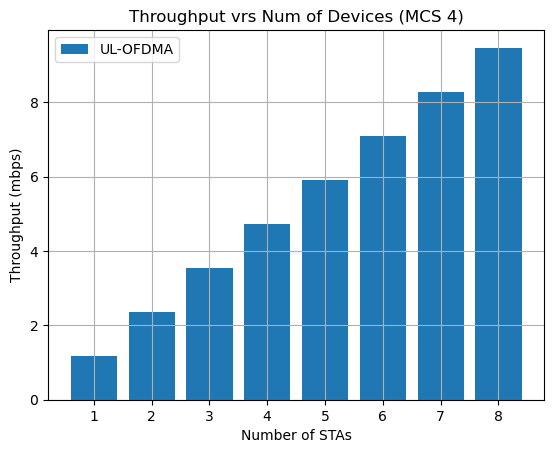

In [38]:
dplt = pd.DataFrame()
dtl = {}
dt = None
dplt1 = pd.DataFrame()
dtl1 = {}
dt1 = None
for mcs in range(4, 5):
    for runs in range(1, 6):
        dtl["nSta"] = []
        dtl["Avg throughput_{runs}".format(runs=runs)] = []
        
        dtl1["nSta"] = []
        dtl1["Avg throughput_{runs}".format(runs=runs)] = []
        
        for nSta in range(1, 9):
            dt = pd.read_csv("results_MUedca/{runs}-uplinkOFDMA-{nSta}-mcs{mcs}/throughput.out".format(nSta=nSta, mcs=mcs, runs=runs), delimiter="\t")
            dt1 = pd.read_csv("results_NOedca/{runs}-uplinkOFDMA-{nSta}-mcs{mcs}/throughput.out".format(nSta=nSta, mcs=mcs, runs=runs), delimiter="\t")
            #print(dt)
            dtl["nSta"].append(nSta)
            dtl["Avg throughput_{runs}".format(runs=runs)].append (dt["Throughput_Mbps"].mean())
            
            dtl1["nSta"].append(nSta)
            dtl1["Avg throughput_{runs}".format(runs=runs)].append (dt["Throughput_Mbps"].mean())
            
    dplt = pd.DataFrame(dtl)
    dplt["Avg Throughput"] = dplt.iloc[:, 1:].mean(axis=1)
    
    dplt1 = pd.DataFrame(dtl)
    dplt1["Avg Throughput"] = dplt.iloc[:, 1:].mean(axis=1)
    #plt.figure()
    #plt.plot(dplt["nSta"], dplt["Avg Throughput"], linestyle='dashed', linewidth = 2,
     #   marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    #plt.bar(dplt["nSta"], dplt["Avg Throughput"], label="UL-OFDMA-MUEDCA", color ='black')
    plt.bar(dplt1["nSta"], dplt1["Avg Throughput"], label="UL-OFDMA")
    plt.xlabel("Number of STAs")
    plt.ylabel("Throughput (mbps)")
    plt.legend()
    plt.grid(True)
    plt.title("Throughput vrs Num of Devices (MCS 4)")
    #plt.savefig("throughput_vrs_Ndev_NOedca.png", dpi=500)

In [8]:
dplt

,nSta,Avg Delay_1,Avg Delay_2,Avg Delay_3,Avg Delay_4,Avg Delay_5,Avg Delay
0,8,0.877703,1.34333,0.702198,0.683106,0.68756,0.858779


In [4]:
for nSta in range(1, 21):
    dtk = pd.read_csv("results/3-downlink-withOfdma-{nSta}-mcs11/per_sta_stats.out".format(nSta=nSta, mcs=mcs, runs=runs), delimiter="\t")
    print(dtk["Avg_delay_ms"].mean())

nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan
nan


In [3]:
dt = pd.read_csv("results/1-downlink-withOfdma-8-mcs11/per_sta_pktdist.out", delimiter="\t")

In [4]:
dt4["Delay_ms"].max()

2.28094

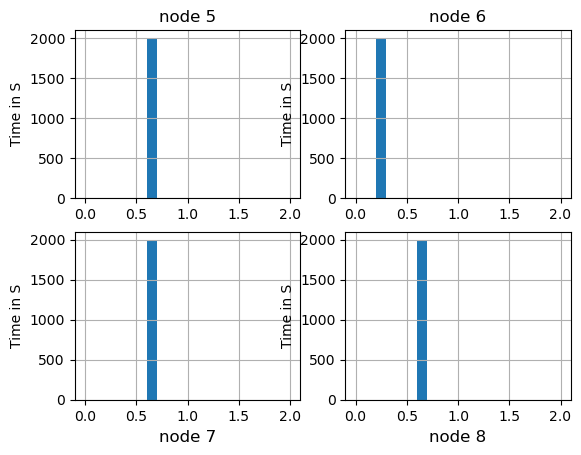

In [4]:
dt1 = pd.read_csv("results/1-downlink-withOfdma-8-mcs11/00:00:00:00:00:05", delimiter="\t")
dt2 = pd.read_csv("results/1-downlink-withOfdma-8-mcs11/00:00:00:00:00:06", delimiter="\t")
dt3 = pd.read_csv("results/1-downlink-withOfdma-8-mcs11/00:00:00:00:00:07", delimiter="\t")
dt4 = pd.read_csv("results/1-downlink-withOfdma-8-mcs11/00:00:00:00:00:08", delimiter="\t")
figure, axis = plt.subplots(2, 2)
axis[0,0].hist(dt1["Delay_ms"], bins=[0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0])
axis[0,0].set_ylabel("Time in S")
#axis[0,0].set_xlabel("Delay_ms")
axis[0,0].grid(True)
axis[0,0].set_title("node 5")

axis[0,1].hist(dt2["Delay_ms"], bins=[0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0])
axis[0,1].set_ylabel("Time in S")
#axis[0,1].set_xlabel("Delay_ms")
axis[0,1].grid(True)
axis[0,1].set_title("node 6")

axis[1,0].hist(dt3["Delay_ms"], bins=[0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0])
axis[1,0].set_ylabel("Time in S")
#axis[1,0].set_xlabel("Delay_ms")
axis[1,0].grid(True)
axis[1,0].set_title("node 7",y=-0.3)

axis[1,1].hist(dt4["Delay_ms"], bins=[0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0])
axis[1,1].set_ylabel("Time in S")
#axis[1,1].set_xlabel("Delay_ms")
axis[1,1].grid(True)
axis[1,1].set_title("node 8",y=-0.3)

#plt.ylabel("Frequency")
#plt.xlabel("Delay (ms)")
#plt.grid(True)
#plt.title("Packet Delay distribution(#dev1,mcs11,rtsoff)")
plt.savefig("Delay_dist_dev8_mcs11_4in1_2_cut_outliers_bsrp_ul_off", dpi=500)

In [14]:
dt4["Delay_ms"].max()

1.27952

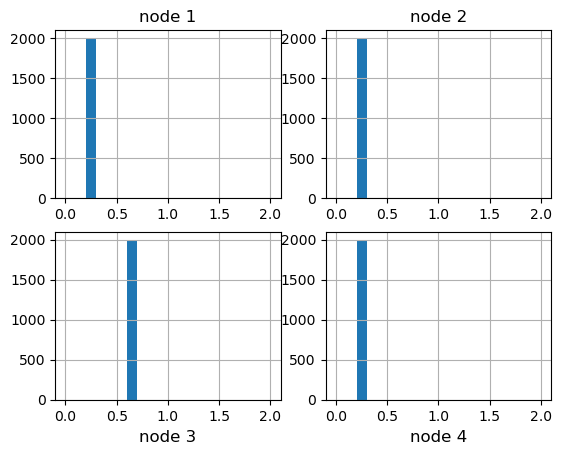

In [5]:
dt1 = pd.read_csv("results/1-downlink-withOfdma-8-mcs11/00:00:00:00:00:01", delimiter="\t")
dt2 = pd.read_csv("results/1-downlink-withOfdma-8-mcs11/00:00:00:00:00:02", delimiter="\t")
dt3 = pd.read_csv("results/1-downlink-withOfdma-8-mcs11/00:00:00:00:00:03", delimiter="\t")
dt4 = pd.read_csv("results/1-downlink-withOfdma-8-mcs11/00:00:00:00:00:04", delimiter="\t")
figure, axis = plt.subplots(2, 2)
axis[0,0].hist(dt1["Delay_ms"], bins=[0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0])
axis[0,0].grid(True)
axis[0,0].set_title("node 1")

axis[0,1].hist(dt2["Delay_ms"], bins=[0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0])
axis[0,1].grid(True)
axis[0,1].set_title("node 2")

axis[1,0].hist(dt3["Delay_ms"], bins=[0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0])
axis[1,0].grid(True)
axis[1,0].set_title("node 3", y=-0.3)

axis[1,1].hist(dt4["Delay_ms"], bins=[0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0])
axis[1,1].grid(True)
axis[1,1].set_title("node 4", y=-0.3)

#plt.ylabel("Frequency")
#plt.xlabel("Delay (ms)")
#plt.grid(True)
#plt.title("Packet Delay distribution(#dev8,mcs11,rtsoff, outliers cut)")
plt.savefig("Delay_dist_dev8_mcs11_4in1_1_cut_outliers_bsrp_ul_off", dpi=500)

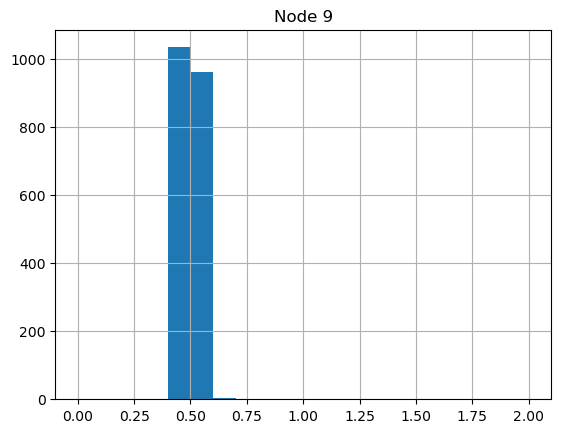

In [10]:
dt5 = pd.read_csv("results/1-downlink-withOfdma-9-mcs11/00:00:00:00:00:09", delimiter="\t")
plt.hist(dt5["Delay_ms"], bins=[0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,1.9,2.0])
plt.grid(True)
plt.title("Node 9")
plt.savefig("Delay_dist_dev9_mcs11_9", dpi=500)

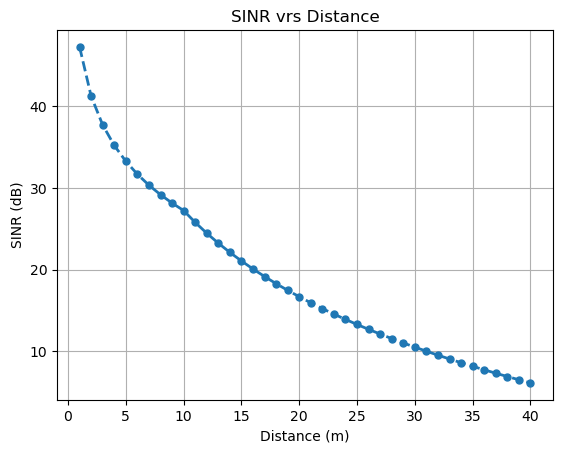

In [10]:
dic = {
    "distance":[],
    "sinr":[]
}
m_frequency = 5150000000
m_exponent1 = 2
m_exponent2 = 3.5
m_breakpointDistance = 10
noise = 10.0 * math.log10(4.01237e-13) + 30.0 


for distance in range(1,41):
    if distance > m_breakpointDistance:
        added_value = 10 * m_exponent2 * math.log10 (distance / m_breakpointDistance)
    else:
        added_value = 0
    pathLossDb = (10 * m_exponent1 * math.log10 (m_frequency) + 10 * m_exponent1 * math.log10 (min (distance, m_breakpointDistance)) - 147.5 ) + added_value;
    #pathLossDb = (0 - pathLossDb) + 30
    #to_W = math.pow(10.0, 0.1 * (-pathLossDb - 30.0))
    #ratio_W = to_W / noise
                    
    dic["distance"].append(distance)
    dic["sinr"].append( -pathLossDb - noise)
    #print(f"{-pathLossDb}\t{added_value}")
df_plt= pd.DataFrame(dic)
#plt.figure()
plt.plot(df_plt["distance"],df_plt["sinr"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5)
plt.xlabel("Distance (m)")
plt.ylabel("SINR (dB)")
#plt.legend()
plt.grid(True)
plt.title("SINR vrs Distance")
plt.savefig("sinr_vs_distance", dpi=500)

In [44]:
dic

{'distance': [1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22,
  23,
  24,
  25,
  26,
  27,
  28,
  29,
  30,
  31,
  32,
  33,
  34,
  35,
  36,
  37,
  38,
  39,
  40],
 'sinr': [47.22984567332665,
  41.209245760047025,
  37.6874205789334,
  35.1886458467674,
  33.250445586606276,
  31.666820665653773,
  30.327884873041512,
  29.168045933487775,
  28.144995484540146,
  27.22984567332665,
  25.781101692788766,
  24.458502061659786,
  23.241828342587368,
  22.11536442458832,
  21.066651606377803,
  20.085646280369275,
  19.16413342508706,
  18.29530799471094,
  17.473469639977637,
  16.693795825087307,
  15.952170357639474,
  15.245051844549437,
  14.569371412710893,
  13.922452213420442,
  13.301945369805338,
  12.705778494348024,
  12.132113927762092,
  11.579314576348978,
  11.045915746863187,
  10.53060175813846,
  10.032186389127105,
  9.549596432129931,
  9.08185777760059,
  8.628083576847729,
  8.1874641210

In [41]:
math.pow(10.0, 0.1 * (-93.96599025415048 - 30.0))

4.012369999999985e-13

In [3]:
for i in range(9, 40, 3):
    print(i)

9
12
15
18
21
24
27
30
33
36
39


In [4]:
run = range (1, 6)
mcs = range (0, 12)
nStations = range (9, 40, 3)


index = pd.MultiIndex.from_product([run, mcs, nStations ], names = ["run","mcs","nStations", ])

pd.DataFrame(index = index).reset_index().to_csv("edca_limit.csv", index=False)

## Televic Scenario

In [5]:
dplt = pd.DataFrame(columns=["Pkt Tag","Avg Delay"])

for mcs in range(11, 12):
    for nSta in range(8, 9):
        for node in range(9, 10): 
            dt = pd.read_csv("results/1-withEdca-{nSta}-mcs{mcs}/00:00:00:00:00:0{node}".format(nSta=nSta, mcs=mcs,node=node), delimiter="\t")
            
            
            
            
            #dplt.loc[nSta] = [nSta, dt["Avg_delay_ms"].mean()]
            #plt.figure()
            #plt.scatter(dt["Delay_ms"], dt["Time_s"])# s=area, c=colors, alpha=0.5)
                        #linestyle='dashed', linewidth = 2, marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
            #plt.ylabel("Time in S")
            #plt.xlabel("Delay_ms")
            #plt.grid(True)
            #plt.legend()
            #plt.title("Node {node}".format(node=node))
            #plt.savefig("Time_vrs_delay_scatter_mcs{node}.png".format(node=node), dpi=500)

In [6]:
dt

,Packet_Tag,Delay_ms
0,24,1.078310
1,24,1.078330
2,24,1.078340
3,24,1.078340
4,24,1.078340
...,...,...
29544,1997,0.926262
29545,1997,0.926268
29546,1997,0.926275
29547,1997,0.926303
